In [14]:
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)


In [16]:
df = pd.read_csv("data.csv")


In [17]:
print("First five rows:")
print(df.head())
print("\nDataset shape:", df.shape)
print("\nColumn information:")
print(df.info())
print("\nMissing values per column:")
print(df.isnull().sum())

First five rows:
  diagnosis  mean radius  mean texture  mean perimeter  mean area  \
0         M        17.99         10.38          122.80     1001.0   
1         M        20.57         17.77          132.90     1326.0   
2         M        19.69         21.25          130.00     1203.0   
3         M        11.42         20.38           77.58      386.1   
4         M        20.29         14.34          135.10     1297.0   

   mean smoothness  mean compactness  mean concavity  mean concave points  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   mean symmetry  ...  worst radius  worst texture  worst perimeter  \
0         0.2419  ...         25.3

In [18]:
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")


In [19]:
df = df.dropna(subset=["diagnosis"])


In [20]:
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})

In [21]:
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]


In [22]:
X = X.apply(pd.to_numeric, errors="coerce")


In [23]:
X = X.apply(pd.to_numeric, errors="coerce")


In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

imputer = SimpleImputer(strategy="median")
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

In [25]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
)
model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [26]:
y_pred = model.predict(X_test)

In [27]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

In [28]:
print("\n--- Model Evaluation ---")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")
print("\nConfusion Matrix (rows = actual, columns = predicted)")
print("Class order: 0 = Benign, 1 = Malignant")
print(cm)


--- Model Evaluation ---
Accuracy : 0.9737
Precision: 1.0000
Recall   : 0.9286
F1-Score : 0.9630

Confusion Matrix (rows = actual, columns = predicted)
Class order: 0 = Benign, 1 = Malignant
[[72  0]
 [ 3 39]]


In [29]:
feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns,
).sort_values(ascending=False)


In [30]:
print("\nTop 10 Important Features:")
print(feature_importance.head(10))



Top 10 Important Features:
worst area              0.155835
worst concave points    0.126547
worst perimeter         0.096288
mean concave points     0.085773
mean perimeter          0.078001
worst radius            0.076126
mean concavity          0.055498
mean radius             0.048280
mean area               0.040874
worst concavity         0.033672
dtype: float64


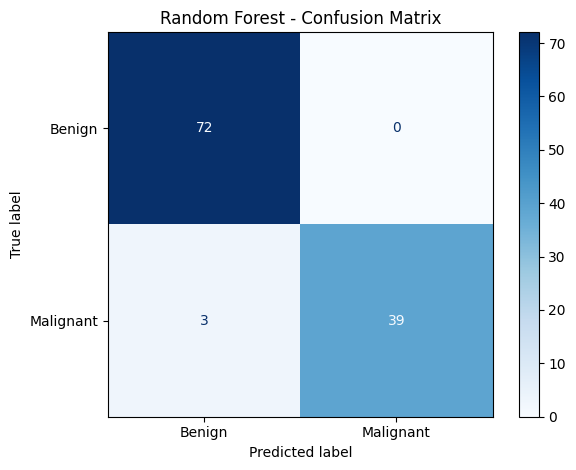

In [31]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"],
).plot(cmap="Blues")
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()


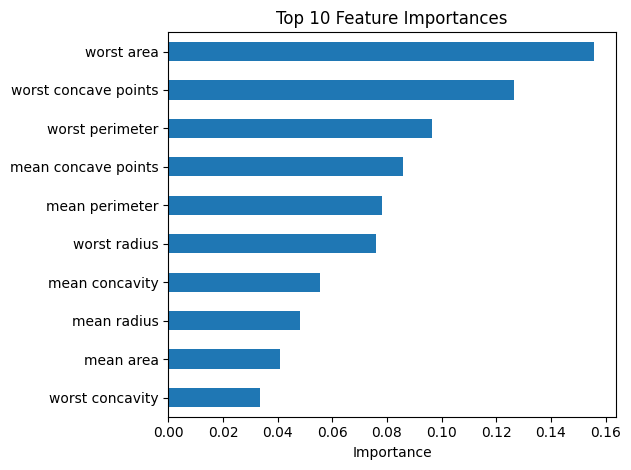

In [32]:
feature_importance.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


In [33]:
print(
    "\nConclusion: The Random Forest classifier was trained to classify "
    "breast tumours as benign or malignant. Review the evaluation metrics "
    "and feature-importance ranking above to understand its performance."
)



Conclusion: The Random Forest classifier was trained to classify breast tumours as benign or malignant. Review the evaluation metrics and feature-importance ranking above to understand its performance.
